In [30]:
import pandas as pd
import numpy as np
import xarray as xr

import matplotlib.pyplot as plt

from scipy.stats import genextreme
from utils.tv_var.periodic_var import PeriodicVAR

In [31]:
import pickle
from utils.pit.piece_wise_marginal import from_normal

point = 'p49'
waves_df = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)
tr_ = pickle.load(open(f"outputs/marginal/transformacion_{point}.pkl", "rb"))
marg, harm_z = tr_["marg"], tr_["harm_z"]

def hs_desde_z(z):
    """Serie de Z (Hs) → Hs en metros, deshaciendo la armónica, Φ y la marginal."""
    zz = pd.DataFrame({"VHM0": z, "VTM02": 0.0}, index=z.index)      # la armónica se ajustó con las dos columnas
    z0 = harm_z.inverse_transform(zz)["VHM0"].clip(-6.36, 6.36)    # mismo límite que to_normal (eps=1e-10)
    return pd.Series(marg["VHM0"].ppf(from_normal(z0).values), index=z.index)

SUF = "_simple"                                   # "" para el modelo completo

#### Validación de extremos: máximos anuales (1985–2025)
Modelo final de 05C (f suavizada + escala + mapeo, en `escala.pkl`), simulado con la f histórica. Cada simulación da 41 máximos anuales que se comparan con los observados.

In [32]:
#### Residuos de 04B y modelo final exportado en 05C
resid = pd.read_csv(f"outputs/xgb_pit_{point}/residuos_horarios.csv", index_col=0, parse_dates=True)
esc = pickle.load(open(f"outputs/xgb_pit_{point}/escala{SUF}.pkl", "rb"))

bordes, sigma, pools_r, results_u, L = esc["bordes"], esc["sigma"], esc["pools_r"], esc["results_u"], esc["L"]

SUAVIZADO_H = esc.get("suavizado_h", 1)
if SUAVIZADO_H > 1:
    resid["f"] = resid["f"].rolling(SUAVIZADO_H, center=True, min_periods=1).mean()
    resid["r"] = resid["z"] - resid["f"]
print(f"f suavizada {SUAVIZADO_H} h")

e_u = results_u.resid_["r"].asfreq("h")
ev = e_u.values
inicios = np.flatnonzero(np.convolve(~np.isnan(ev), np.ones(L), "valid") == L)

def ruido_bloques(n, L, rng):
    out = np.empty(n)
    t = 0
    while t < n:
        s = rng.choice(inicios)
        m = min(L, n - t)
        out[t:t + m] = ev[s:s + m]
        t += m
    return out

def mapear(r, dec):
    """Mapeo de cuantiles por decil: r toma la forma de r_oof de su decil."""
    out = np.empty(len(r))
    for k in range(10):
        m = dec == k
        rk = (pd.Series(r.values[m]).rank().values - 0.5) / m.sum()
        out[m] = np.quantile(pools_r[k], rk)
    return pd.Series(out, index=r.index)

f suavizada 1 h


In [33]:
f_all = resid.loc["1985-01-01":"2025-12-31", "f"].asfreq("h")
hs_all = waves_df.loc["1985":"2025", "VHM0"]
dec_all = np.digitize(f_all, bordes)
sig_all = pd.Series(sigma.loc[dec_all].values, index=f_all.index)

import time
n_sims = 30
hs_sims = []
for i in range(n_sims):
    t = time.time()
    rng = np.random.default_rng(i)
    ruido_df = pd.DataFrame(ruido_bloques(len(f_all), L, rng), index=f_all.index, columns=["r"])
    u_i = results_u.simulate(noise=ruido_df, burn=24*30)["r"]
    hs_sims.append(hs_desde_z(f_all + mapear(u_i * sig_all, dec_all)))
    print(f"sim {i:02d} ({time.time() - t:.0f} s)")
hs_sims = pd.concat(hs_sims, axis=1)
hs_sims.to_pickle(f"outputs/xgb_pit_{point}/hs_sims_1985_2025{SUF}.pkl")

sim 00 (11 s)
sim 01 (11 s)
sim 02 (11 s)
sim 03 (12 s)
sim 04 (11 s)
sim 05 (11 s)
sim 06 (12 s)
sim 07 (11 s)
sim 08 (11 s)
sim 09 (11 s)
sim 10 (10 s)
sim 11 (11 s)
sim 12 (10 s)
sim 13 (10 s)
sim 14 (11 s)
sim 15 (10 s)
sim 16 (10 s)
sim 17 (10 s)
sim 18 (11 s)
sim 19 (11 s)
sim 20 (11 s)
sim 21 (10 s)
sim 22 (11 s)
sim 23 (11 s)
sim 24 (11 s)
sim 25 (11 s)
sim 26 (11 s)
sim 27 (11 s)
sim 28 (11 s)
sim 29 (11 s)


años con el máximo observado dentro del 95 % simulado: 83%  (esperado ≈ 95 %)
por encima: 2% | por debajo: 15%
media máx. anual: obs 3.97 | sim 4.41 [4.17–4.56]
corr año a año (obs vs mediana sim): 0.68


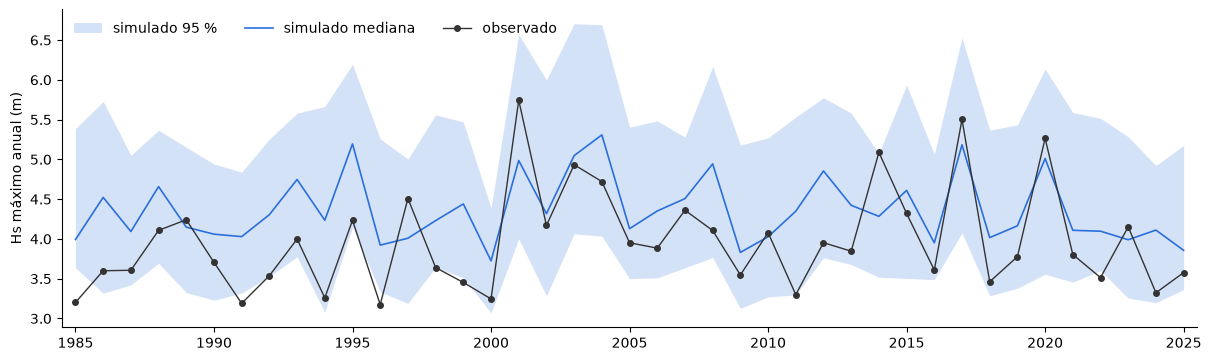

In [34]:
#### Máximos anuales
am_obs = hs_all.groupby(hs_all.index.year).max()
am_sim = hs_sims.groupby(hs_sims.index.year).max()            # (41 años, n_sims)
lo, med, hi = am_sim.quantile(0.025, axis=1), am_sim.median(axis=1), am_sim.quantile(0.975, axis=1)

dentro = ((am_obs >= lo) & (am_obs <= hi)).mean()
print(f"años con el máximo observado dentro del 95 % simulado: {dentro:.0%}  (esperado ≈ 95 %)")
print(f"por encima: {(am_obs > hi).mean():.0%} | por debajo: {(am_obs < lo).mean():.0%}")
print(f"media máx. anual: obs {am_obs.mean():.2f} | sim {am_sim.mean().median():.2f} [{am_sim.mean().quantile(0.025):.2f}–{am_sim.mean().quantile(0.975):.2f}]")
print(f"corr año a año (obs vs mediana sim): {am_obs.corr(med):.2f}")

fig, ax = plt.subplots(figsize=(12, 3.5), constrained_layout=True)
ax.fill_between(am_sim.index, lo, hi, color="#2a6fdb", alpha=0.2, lw=0, label="simulado 95 %")
ax.plot(med, color="#2a6fdb", lw=1.2, label="simulado mediana")
ax.plot(am_obs, "o-", color="0.2", ms=4, lw=1, label="observado")
ax.set(ylabel="Hs máximo anual (m)", xlim=(am_obs.index[0] - 0.5, am_obs.index[-1] + 0.5))
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", ncol=3)
plt.show()

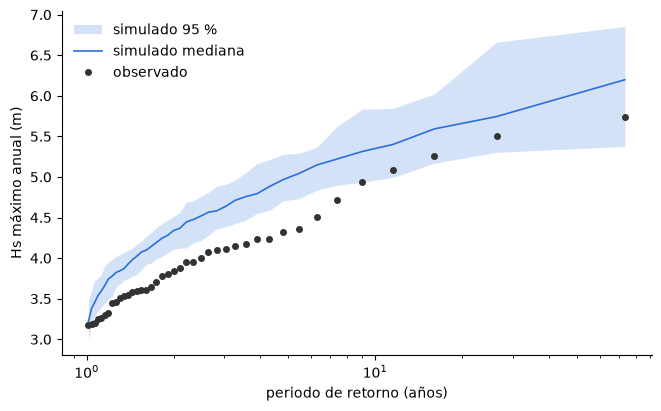

In [35]:
#### Curva de periodos de retorno empírica (Gringorten): obs vs banda de las simulaciones
n = len(am_obs)
T = 1 / (1 - (np.arange(1, n + 1) - 0.44) / (n + 0.12))           # periodo de retorno de cada orden
am_sim_ord = np.sort(am_sim.values, axis=0)                       # (n, n_sims), cada simulación ordenada

fig, ax = plt.subplots(figsize=(6.5, 4), constrained_layout=True)
ax.fill_between(T, np.percentile(am_sim_ord, 2.5, axis=1), np.percentile(am_sim_ord, 97.5, axis=1),
                color="#2a6fdb", alpha=0.2, lw=0, label="simulado 95 %")
ax.plot(T, np.median(am_sim_ord, axis=1), color="#2a6fdb", lw=1.2, label="simulado mediana")
ax.plot(T, np.sort(am_obs.values), "o", color="0.2", ms=4, label="observado")
ax.set(xscale="log", xlabel="periodo de retorno (años)", ylabel="Hs máximo anual (m)")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.show()

In [36]:
#### GEV: parámetros y niveles de retorno, obs vs simulaciones
T_ret = np.array([2, 10, 50, 100])

def gev(am):
    c_, loc, scale = genextreme.fit(am)
    return {"ξ": -c_, "μ": loc, "σ": scale, **{f"Hs{t}": genextreme.ppf(1 - 1 / t, c_, loc, scale) for t in T_ret}}

g_obs = pd.Series(gev(am_obs.values))
g_sim = pd.DataFrame([gev(am_sim[c_].values) for c_ in am_sim.columns])
tabla_gev = pd.DataFrame({"obs": g_obs, "sim med": g_sim.median(), "sim lo": g_sim.quantile(0.025), "sim hi": g_sim.quantile(0.975)})
print(tabla_gev.round(2).to_string())
print("ojo: con 41 años, ξ y Hs100 tienen mucha incertidumbre también en lo observado")

        obs  sim med  sim lo  sim hi
ξ      0.16    -0.09   -0.33    0.12
μ      3.65     4.12    3.94    4.25
σ      0.43     0.57    0.49    0.70
Hs2    3.81     4.33    4.14    4.49
Hs10   4.80     5.31    5.01    5.58
Hs50   5.95     6.05    5.36    6.89
Hs100  6.53     6.30    5.45    7.54
ojo: con 41 años, ξ y Hs100 tienen mucha incertidumbre también en lo observado


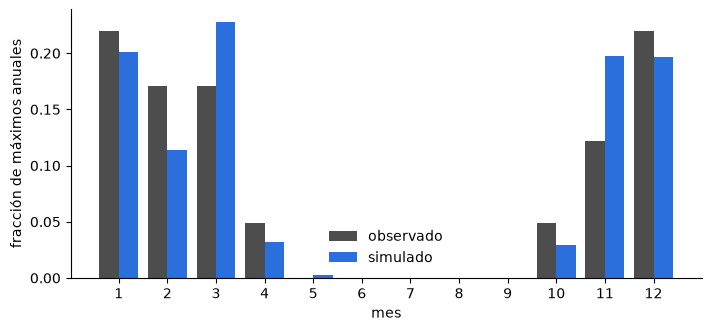

In [37]:
#### ¿En qué mes cae el máximo anual?
mes_obs = hs_all.groupby(hs_all.index.year).idxmax().dt.month
mes_sim = pd.concat([hs_sims[c_].groupby(hs_sims.index.year).idxmax().dt.month for c_ in hs_sims.columns])
frec = pd.DataFrame({"obs": mes_obs.value_counts(normalize=True), "sim": mes_sim.value_counts(normalize=True)}).reindex(range(1, 13)).fillna(0)

fig, ax = plt.subplots(figsize=(7, 3.2), constrained_layout=True)
ax.bar(frec.index - 0.2, frec["obs"], width=0.4, color="0.3", label="observado")
ax.bar(frec.index + 0.2, frec["sim"], width=0.4, color="#2a6fdb", label="simulado")
ax.set(xticks=range(1, 13), xlabel="mes", ylabel="fracción de máximos anuales")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()